# 02 - Feature Engineering & Preprocessing

**Goal:** turn raw sessions into model-ready features *without leakage*.

**Approach:** all learned transforms live inside a scikit-learn Pipeline so they are fitted on training folds only.

In [1]:
import sys, warnings
sys.path.insert(0, "..")
warnings.filterwarnings("ignore")
import logging; logging.disable(logging.INFO)
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from src.config.settings import get_settings
from src.data.loader import load_dataset
S = get_settings()
df = load_dataset(S)
sns.set_theme(style="whitegrid")
from src.features.engineering import BehaviourFeatures
from src.preprocessing.pipeline import build_pipeline, transformed_feature_names
from src.models.trainers import get_trainer
from src.data.loader import SessionDataLoader

## 1. Engineered behaviour features
| Feature | Idea |
|---|---|
| `TotalPages`, `TotalDuration` | overall engagement |
| `AvgTimePerPage` | attention per page (skimmers vs readers) |
| `ProductPageShare` | share of the visit spent shopping |
| `TimePerProductPage` | how carefully products are examined |
| `IsReturning` | returning-visitor flag |

In [2]:
feats = BehaviourFeatures.from_settings().transform(df[S.input_columns])
new = S.engineered_features
out = feats[new].assign(Converted=df['Converted'])
print(out.groupby('Converted').median().round(2))
out.corr()['Converted'].drop('Converted').round(3)

           TotalPages  TotalDuration  AvgTimePerPage  ProductPageShare  \
Converted                                                                
0                18.0         505.26           29.02              0.88   
1                35.0        1008.91           29.33              0.92   

           TimePerProductPage  IsReturning  
Converted                                   
0                       29.87          1.0  
1                       29.64          1.0  


TotalPages            0.477
TotalDuration         0.303
AvgTimePerPage        0.008
ProductPageShare      0.150
TimePerProductPage    0.000
IsReturning           0.058
Name: Converted, dtype: float64

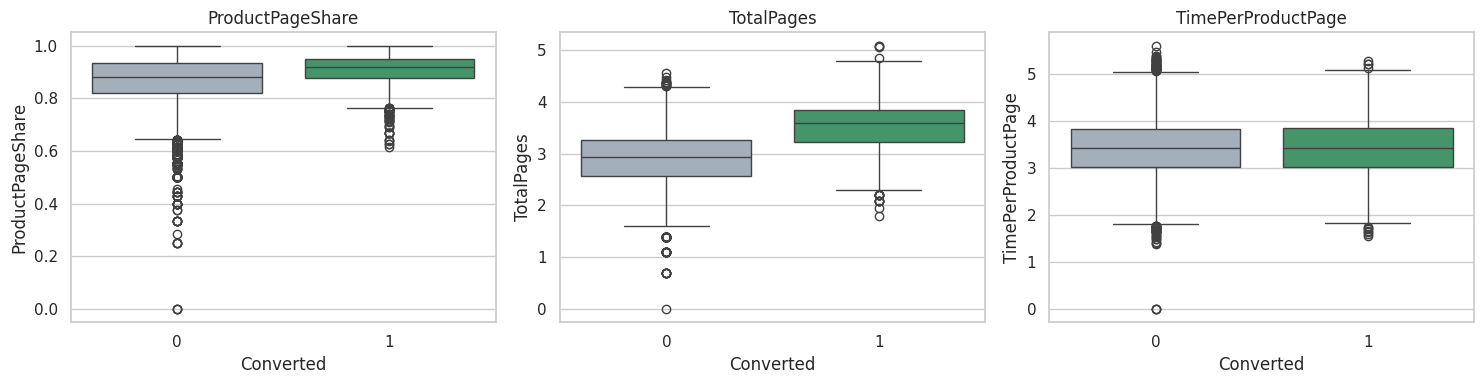

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ['ProductPageShare', 'TotalPages', 'TimePerProductPage']):
    sns.boxplot(data=out, x='Converted', y=np.log1p(out[col]) if col != 'ProductPageShare' else out[col], ax=ax, palette=['#a0aec0', '#38a169'])
    ax.set_title(col)
plt.tight_layout(); plt.show()

**Reading (honest):** `TotalPages` (corr ~0.48) and `TotalDuration` (~0.30) carry real signal - buyers browse about twice as many pages. `ProductPageShare` is weak (~0.15) and `AvgTimePerPage` / `TimePerProductPage` show **almost no marginal signal** (~0.00). They are kept because they are cheap, interpretable and harmless, but they are not where the model's power comes from; the raw `PageValues`, `ExitRates` and page counts are.

## 2. Preprocessing design
- **Right-skewed counts/durations/PageValues** -> `log1p` then `RobustScaler` (robust to outliers).
- **Bounded rates** -> `RobustScaler` only.
- **Month, VisitorType and the 4 ID columns** -> `OneHotEncoder(handle_unknown='ignore')` so an unseen browser code at serving time does not crash.
- **Weekend, IsReturning** -> passthrough 0/1.

In [4]:
loader = SessionDataLoader(S)
X_tr, X_te, y_tr, y_te = loader.split(df)
pipe = build_pipeline(get_trainer('logistic_regression').build(), 'none', S).fit(X_tr, y_tr)
names = transformed_feature_names(pipe)
print(len(names), 'model-ready columns')
for col in S.id_categorical_columns:
    n = sum(x.startswith(f'cat__{col}_') for x in names)
    print(f'{col:18s} -> {n} one-hot columns (never scaled as a number)')

80 model-ready columns
OperatingSystems   -> 8 one-hot columns (never scaled as a number)
Browser            -> 13 one-hot columns (never scaled as a number)
Region             -> 9 one-hot columns (never scaled as a number)
TrafficType        -> 20 one-hot columns (never scaled as a number)


## 3. Imbalance handling lives *inside* cross-validation
`SMOTE` is a pipeline step, so synthetic samples are generated from **training folds only**. Applying SMOTE to the whole dataset first would leak synthetic neighbours of validation rows into training and inflate scores.

In [5]:
p = build_pipeline(get_trainer('xgboost').build('smote'), 'smote', S)
print([name for name, _ in p.steps])

['features', 'prep', 'sampler', 'clf']


## 4. The `PageValues` switch
`features.use_page_values` in `config.yaml` drops the column inside the pipeline. Notebook 03 compares both variants.

In [6]:
without = BehaviourFeatures.from_settings(use_page_values=False).transform(df[S.input_columns].head(3))
print('PageValues' in without.columns)

False


## Takeaways
- 6 engineered features, all computed inside a Pipeline step (same code at serving time).
- ID columns treated as categories; skewed numerics log-transformed.
- No learned transform ever sees validation or test data.